# SuperTrend 交易績效追蹤與回測系統
---
本 Notebook 提供 SuperTrend 交易策略的互動式分析介面。系統支援：
1. **SQLite 本地快取**：自動儲存 Yahoo Finance 歷史資料於本地資料庫中，減少重複請求。
2. **技術指標計算**：計算 SuperTrend, Hull Moving Average (HMA), ADX, RSI。
3. **精確交易回測**：扣除手續費/滑價，處理開盤價跳空止損，支援固定風險比例部位控制。
4. **績效指標評估**：計算 CAGR、最大回撤、夏普比率、索提諾比率、交易期望值與 **Ulcer Index (潰瘍指數)**。
5. **可重現 Monte Carlo 模擬**：分析交易回報序列，展示 95% 及 99% 最壞風險路徑分位數。
6. **參數熱力圖尋優**：藉由 Walk-Forward 劃分尋找參數穩健高原區 (Plateau)。

In [3]:
# Cell 1: 載入核心模組與依賴庫
import pandas as pd
import numpy as np
import plotly.graph_objects as go
from plotly.subplots import make_subplots

from src.data_loader import DataLoader
from src.indicators import compute_supertrend, compute_hma, compute_adx, compute_rsi
from src.backtest_engine import BacktestEngine
from src.risk_manager import RiskManager
from src.optimizer import ParameterOptimizer

print("模組載入成功！")

模組載入成功！


In [13]:
# Cell 2: 下載與載入 ETF 歷史價格資料 (以 SPY 作為預設標的)
ticker = "QQQM"
start_date = "2020-01-01"
end_date = "2026-06-01"
interval = "1d"

loader = DataLoader()
# 優先從本地 SQLite 讀取，缺失時才會下載並快取
df_raw = loader.fetch_data(ticker, start_date=start_date, end_date=end_date, interval=interval, refresh=False)
print(f"成功加載 {ticker} K 線資料：共 {len(df_raw)} 筆記錄。")
df_raw.tail()

[*********************100%***********************]  1 of 1 completed

成功加載 QQQM K 線資料：共 1413 筆記錄。


,Open,High,Low,Close,Volume
datetime,,,,,
2026-05-22,295.348222,296.986310,294.449268,295.098511,2889100.0
2026-05-26,298.554487,300.697027,297.825350,300.332428,3841800.0
2026-05-27,301.451148,301.471144,298.344757,300.032806,3946400.0
2026-05-28,300.122685,302.909469,298.764241,302.499939,4287800.0
2026-05-29,303.458822,304.977054,302.410048,303.608643,3727400.0


In [14]:
# Cell 3: 計算技術指標與執行回測
# 1. 計算 SuperTrend
df_indicators, trend = compute_supertrend(df_raw, period=10, multiplier=3.0)

# 2. 計算 200 日 HMA 均線作為順勢過濾器
df_indicators["HMA"] = compute_hma(df_indicators["Close"], period=200)
df_indicators["MA_Filter"] = df_indicators["Close"] > df_indicators["HMA"]

# 3. 計算 ADX 趨勢強度與 RSI 動能過濾器
df_indicators["ADX"] = compute_adx(df_indicators, period=14)
df_indicators["RSI"] = compute_rsi(df_indicators["Close"], period=14)

# 您可以選擇開啟或關閉 ADX/RSI 過濾器
df_indicators["ADX_Filter"] = True  # 例如：df_indicators["ADX"] > 20
df_indicators["RSI_Filter"] = True  # 例如：df_indicators["RSI"] > 50

# 4. 執行回測 (設定單邊交易摩擦：手續費 10 bps, 滑價 5 bps，部位設 8% 止損與 20% 止利)
engine = BacktestEngine(df_indicators)
trades, strat_equity, bench_equity = engine.run(
    long_only=True,
    stop_loss_pct=0.08,
    take_profit_pct=0.20,
    commission_bps=10.0,
    slippage_bps=5.0,
    position_sizing_mode="fixed_fraction" # 亦可設為 "fixed_risk" 並給定 risk_pct
)

print(f"回測完成！已平倉交易筆數: {len(trades)}")

回測完成！已平倉交易筆數: 10


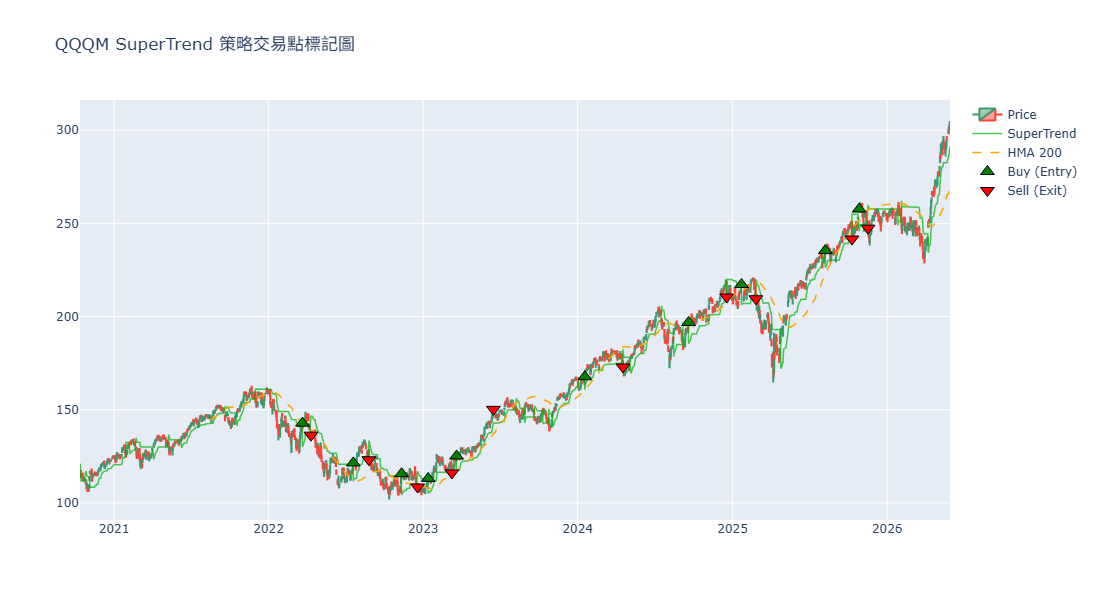

In [15]:
# Cell 4: 繪製價格 K 線、SuperTrend 通道與買賣標記圖 (Plotly 互動式)
fig_price = go.Figure()

# K 線圖
fig_price.add_trace(go.Candlestick(
    x=df_indicators.index,
    open=df_indicators['Open'],
    high=df_indicators['High'],
    low=df_indicators['Low'],
    close=df_indicators['Close'],
    name='Price'
))

# SuperTrend 線
fig_price.add_trace(go.Scatter(
    x=df_indicators.index,
    y=df_indicators['SuperTrend'],
    line=dict(color='rgba(0, 180, 0, 0.7)' if df_indicators['Trend'].iloc[-1] == 1 else 'rgba(180, 0, 0, 0.7)', width=1.5),
    name='SuperTrend'
))

# HMA 200
fig_price.add_trace(go.Scatter(
    x=df_indicators.index,
    y=df_indicators['HMA'],
    line=dict(color='orange', width=1.5, dash='dash'),
    name='HMA 200'
))

# 標記交易進出場點
buy_dates = [t.entry_date for t in trades]
buy_prices = [t.entry_price for t in trades]
sell_dates = [t.exit_date for t in trades]
sell_prices = [t.exit_price for t in trades]

fig_price.add_trace(go.Scatter(
    x=buy_dates, y=buy_prices, mode='markers',
    marker=dict(symbol='triangle-up', size=12, color='green', line=dict(width=1, color='black')),
    name='Buy (Entry)'
))

fig_price.add_trace(go.Scatter(
    x=sell_dates, y=sell_prices, mode='markers',
    marker=dict(symbol='triangle-down', size=12, color='red', line=dict(width=1, color='black')),
    name='Sell (Exit)'
))

fig_price.update_layout(title=f'{ticker} SuperTrend 策略交易點標記圖', xaxis_rangeslider_visible=False, height=600)
fig_price.show()

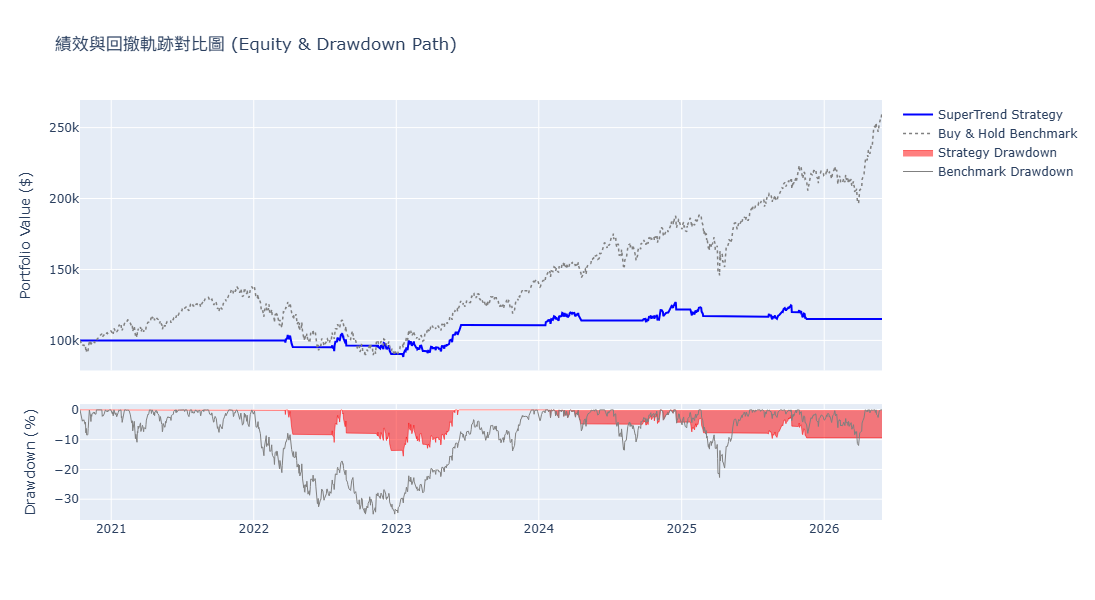

In [16]:
# Cell 5: 繪製策略與 Benchmark 淨值曲線與回撤軌跡對比圖
roll_max_strat = strat_equity.cummax()
dd_strat = (strat_equity - roll_max_strat) / roll_max_strat

roll_max_bench = bench_equity.cummax()
dd_bench = (bench_equity - roll_max_bench) / roll_max_bench

fig_perf = make_subplots(rows=2, cols=1, shared_xaxes=True, vertical_spacing=0.08, row_heights=[0.7, 0.3])

# 淨值對比
fig_perf.add_trace(go.Scatter(x=strat_equity.index, y=strat_equity, name='SuperTrend Strategy', line=dict(color='blue', width=2)), row=1, col=1)
fig_perf.add_trace(go.Scatter(x=bench_equity.index, y=bench_equity, name='Buy & Hold Benchmark', line=dict(color='gray', width=1.5, dash='dot')), row=1, col=1)

# 回撤軌跡
fig_perf.add_trace(go.Scatter(x=dd_strat.index, y=dd_strat * 100, name='Strategy Drawdown', fill='tozeroy', line=dict(color='rgba(255, 0, 0, 0.5)', width=1)), row=2, col=1)
fig_perf.add_trace(go.Scatter(x=dd_bench.index, y=dd_bench * 100, name='Benchmark Drawdown', line=dict(color='gray', width=1)), row=2, col=1)

fig_perf.update_layout(title='績效與回撤軌跡對比圖 (Equity & Drawdown Path)', height=600)
fig_perf.update_yaxes(title_text='Portfolio Value ($)', row=1, col=1)
fig_perf.update_yaxes(title_text='Drawdown (%)', row=2, col=1)
fig_perf.show()

In [17]:
# Cell 6: 多維統計指標與交易明細表
rm = RiskManager(trades, strat_equity)
metrics = rm.calculate_metrics()

print("=== 績效與風險統計指標 (Traditional Chinese) ===")
for key, val in metrics.items():
    if isinstance(val, float):
        if key in ["CAGR", "Max Drawdown", "Ulcer Index", "Win Rate", "Expectancy"]:
            print(f"{key:25s}: {val * 100:.2f}%")
        else:
            print(f"{key:25s}: {val:.2f}")
    else:
        print(f"{key:25s}: {val}")

print("\n=== 最近 5 筆平倉交易明細 ===")
trade_data = [{
    "Entry Date": t.entry_date.strftime("%Y-%m-%d"),
    "Entry Price": round(t.entry_price, 2),
    "Exit Date": t.exit_date.strftime("%Y-%m-%d") if t.exit_date else "Open",
    "Exit Price": round(t.exit_price, 2) if t.exit_price else "Open",
    "PnL (%)": f"{round(t.pnl_pct * 100, 2)}%",
    "Reason": t.exit_reason
} for t in trades]
pd.DataFrame(trade_data).tail(5)

=== 績效與風險統計指標 (Traditional Chinese) ===
CAGR                     : 2.52%
Max Drawdown             : -15.56%
Ulcer Index              : 5.80%
Sharpe Ratio             : 0.10
Sortino Ratio            : 0.08
Win Rate                 : 60.00%
Profit Factor            : 2.02
Calmar Ratio             : 0.16
Expectancy               : 1.86%
Avg Holding Days         : 53.60
Annual Trades            : 1.78
Max Consecutive Wins     : 4
Max Consecutive Losses   : 1

=== 最近 5 筆平倉交易明細 ===


,Entry Date,Entry Price,Exit Date,Exit Price,PnL (%),Reason
5,2024-01-18,167.71,2024-04-17,172.94,3.12%,Signal
6,2024-09-19,196.85,2024-12-18,210.52,6.94%,Signal
7,2025-01-22,217.18,2025-02-25,209.56,-3.51%,Signal
8,2025-08-08,235.45,2025-10-10,241.63,2.62%,Signal
9,2025-10-27,257.73,2025-11-17,247.46,-3.98%,Signal


=== Monte Carlo 5000 次模擬最大回撤分位數報告 ===
50% (Median)        : -20.72%
75%                 : -26.38%
90%                 : -32.50%
95%                 : -36.59%
99%                 : -45.30%


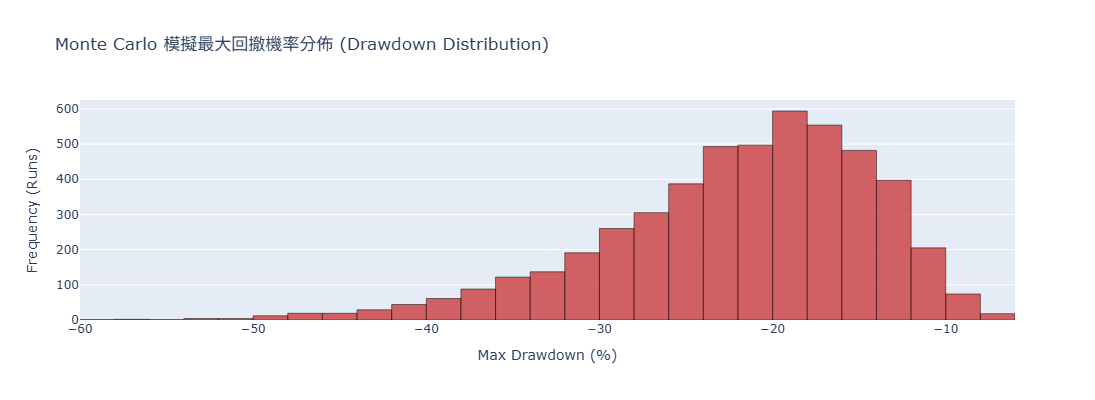

In [18]:
# Cell 7: 可重現 Monte Carlo 風險模擬分析
mc_runs = 5000
mc_trades = 50
mc_seed = 42

mc_results = rm.run_monte_carlo(runs=mc_runs, num_trades=mc_trades, seed=mc_seed)
percentiles = mc_results["percentiles"]

print(f"=== Monte Carlo {mc_runs} 次模擬最大回撤分位數報告 ===")
for pct, val in percentiles.items():
    print(f"{pct:20s}: {val * 100:.2f}%")

# 繪製最大回撤發生機率分佈直方圖
fig_mc = go.Figure()
fig_mc.add_trace(go.Histogram(
    x=mc_results["drawdowns"] * 100,
    nbinsx=50,
    marker=dict(
        color='rgba(200, 50, 50, 0.75)',
        line=dict(color='black', width=0.5)
    )
))
fig_mc.update_layout(title='Monte Carlo 模擬最大回撤機率分佈 (Drawdown Distribution)', xaxis_title='Max Drawdown (%)', yaxis_title='Frequency (Runs)', height=400)
fig_mc.show()

正在執行網格優化掃描，這將耗時約 2-3 秒...

=== 樣本內 (Train) 前五名最穩健參數排名前五名 ===


,ST_Period,ST_Multiplier,MA_Period,Custom Score,CAGR,Max Drawdown,Ulcer Index,Sharpe Ratio,Sortino Ratio,Win Rate,Profit Factor,Calmar Ratio,Expectancy,Avg Holding Days,Annual Trades,Max Consecutive Wins,Max Consecutive Losses
0,7,3.0,150,1.606105,0.105715,-0.138478,0.046237,0.766374,0.790798,0.714286,5.873590,0.763407,0.063642,78.714286,1.780467,3,1
1,7,3.0,100,1.313043,0.122592,-0.138478,0.047252,0.836962,0.930122,0.636364,4.132406,0.885281,0.046549,64.545455,2.797876,3,1
2,10,3.0,150,1.135943,0.080640,-0.150568,0.052384,0.568892,0.581622,0.750000,4.165260,0.535571,0.041457,68.250000,2.034819,4,1
3,7,3.0,200,1.053181,0.062342,-0.138478,0.044325,0.433626,0.398519,0.600000,4.082795,0.450193,0.056359,77.600000,1.271762,2,1
4,10,3.0,100,1.002878,0.096357,-0.150568,0.053311,0.645469,0.717623,0.666667,3.235438,0.639960,0.032942,59.250000,3.052228,3,1


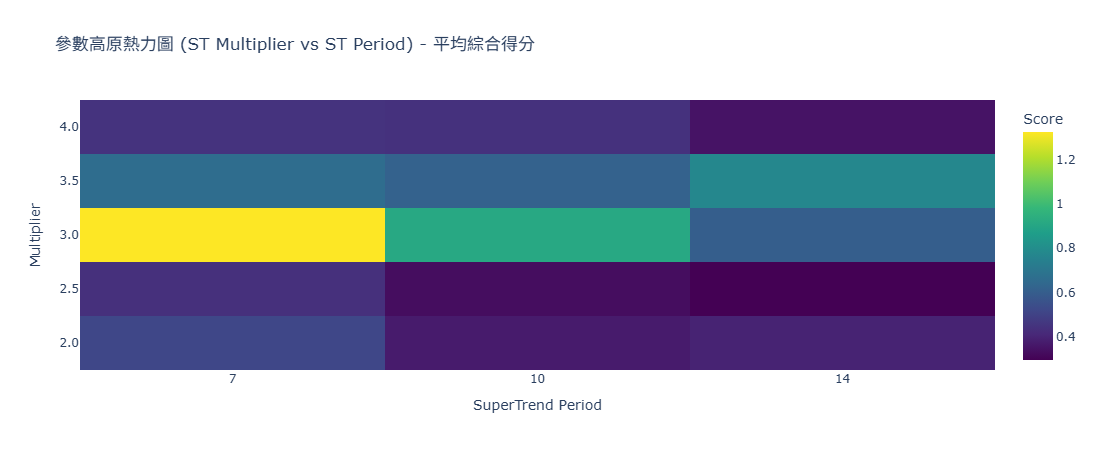

In [19]:
# Cell 8: Walk-Forward 優化與穩健參數高原熱力圖
print("正在執行網格優化掃描，這將耗時約 2-3 秒...")
optimizer = ParameterOptimizer(df_raw)

# 優化搜尋範圍：SuperTrend 長度 7 到 15，倍數 2.0 到 4.0
st_periods = [7, 10, 14]
st_multipliers = [2.0, 2.5, 3.0, 3.5, 4.0]
ma_periods = [100, 150, 200]

# 樣本切割比率為 70% (30% 為樣本外 OOS 測試)
train_res, test_res = optimizer.optimize(
    st_periods=st_periods,
    st_multipliers=st_multipliers,
    ma_periods=ma_periods,
    target_metric="Custom Score",
    train_ratio=0.70
)

print("\n=== 樣本內 (Train) 前五名最穩健參數排名前五名 ===")
display(train_res.head(5))

# 繪製參數熱力圖資料以評估 Plateau 高原區
heatmap_df = train_res.pivot_table(index='ST_Multiplier', columns='ST_Period', values='Custom Score', aggfunc='mean')

fig_hm = go.Figure(data=go.Heatmap(
    z=heatmap_df.values,
    x=heatmap_df.columns.astype(str),
    y=heatmap_df.index.astype(str),
    colorscale='Viridis',
    colorbar=dict(title='Score')
))
fig_hm.update_layout(title='參數高原熱力圖 (ST Multiplier vs ST Period) - 平均綜合得分', xaxis_title='SuperTrend Period', yaxis_title='Multiplier', height=450)
fig_hm.show()

In [20]:
# Cell 9: 查看指定參數組合的完整交易紀錄明細
# 請在下方填寫您想檢視的參數組合（預設為 Cell 8 掃描出的最佳組合示例）
target_st_period = 7
target_st_multiplier = 3
target_ma_period = 150

# 1. 重新計算該組參數的技術指標
df_opt, _ = compute_supertrend(df_raw, period=target_st_period, multiplier=target_st_multiplier)
df_opt["HMA"] = compute_hma(df_opt["Close"], period=target_ma_period)
df_opt["MA_Filter"] = df_opt["Close"] > df_opt["HMA"]
df_opt["ADX_Filter"] = True  # 同步您的過濾器設定
df_opt["RSI_Filter"] = True  # 同步您的過濾器設定

# 2. 重新執行該特定參數組合的回測
engine_opt = BacktestEngine(df_opt)
opt_trades, opt_equity, _ = engine_opt.run(
    long_only=True,
    stop_loss_pct=0.08,
    take_profit_pct=0.20,
    commission_bps=10.0,
    slippage_bps=5.0
)

# 3. 輸出詳細交易歷史清單
opt_trade_list = [{
    "交易序號": idx + 1,
    "方向": t.direction,
    "進場日期": t.entry_date.strftime("%Y-%m-%d"),
    "實際買入價 (含滑價/手續費)": round(t.entry_price, 2),
    "出場日期": t.exit_date.strftime("%Y-%m-%d") if t.exit_date else "未平倉",
    "實際賣出價 (含滑價/手續費)": round(t.exit_price, 2) if t.exit_price else "未平倉",
    "單筆損益 (%)": f"{round(t.pnl_pct * 100, 2)}%",
    "離場原因": t.exit_reason
} for idx, t in enumerate(opt_trades)]

df_opt_trades = pd.DataFrame(opt_trade_list)
print(f"=== 參數組合 ST({target_st_period}, {target_st_multiplier}) + HMA({target_ma_period}) 的完整交易紀錄 (共 {len(df_opt_trades)} 筆) ===")
df_opt_trades

=== 參數組合 ST(7, 3) + HMA(150) 的完整交易紀錄 (共 14 筆) ===


,交易序號,方向,進場日期,實際買入價 (含滑價/手續費),出場日期,實際賣出價 (含滑價/手續費),單筆損益 (%),離場原因
0,1,Long,2021-06-10,135.42,2021-09-20,145.81,7.67%,Signal
1,2,Long,2022-03-22,142.80,2022-04-11,136.36,-4.51%,Signal
2,3,Long,2022-07-20,121.47,2022-08-26,123.17,1.4%,Signal
3,4,Long,2022-11-11,115.67,2022-12-16,110.09,-4.82%,Signal
4,5,Long,2023-01-13,113.15,2023-05-18,135.71,19.94%,TakeProfit
5,6,Long,2023-11-03,148.84,2024-01-03,161.46,8.48%,Signal
6,7,Long,2024-01-18,167.71,2024-04-15,175.04,4.37%,Signal
7,8,Long,2024-09-19,196.85,2024-12-18,210.52,6.94%,Signal
8,9,Long,2025-01-22,217.18,2025-02-24,212.21,-2.29%,Signal
9,10,Long,2025-05-01,196.97,2025-08-01,226.76,15.13%,Signal
